# Connectivity-Informed EEG Source Reconstruction via Weighted

Connectome Harmonics

Nino Herve (Lausanne University Hospital and University of Lausanne (CHUV-UNIL))  
Yasser Alemán-Gómez (Lausanne University Hospital and University of Lausanne (CHUV-UNIL))  
Emma Depuydt (Ghent University)  
Pieter Van Mierlo (Ghent University)  
Nicolas Roehri (University Hospitals and Faculty of Medicine, University of Geneva)  
Patric Hagmann (Lausanne University Hospital and University of Lausanne (CHUV-UNIL))

# Introduction

Source reconstruction is an ill-posed problem whose reliability depends on how well the prior reflects neural physiology. Classical Bayesian methods assume independent, Gaussian-distributed sources based on Occam’s Razor, an assumption underlying sLORETA, eLORETA, beamformers, and dSPM. Yet neural sources interact, and independence priors fail to capture this structure. Attempts to include source interactions—such as using fMRI-derived covariance matrices Liu et al. ([2021](#ref-liu_fmri-si-stbf_2021)) or estimating the covariance jointly with the sources Gonzalez-Moreira et al. ([2018](#ref-gonzalez-moreira_caulking_2018)) —either suffer from modality mismatch or greatly increase model complexity, and have rarely been tested on interacting sources.

A recent approach, Connectome Spectrum Electromagnetic Tomography (CSET) Rué‐Queralt et al. ([2024](#ref-ruequeralt_connectome_2024)), uses insights from connectomics, which represents the brain as a graph whose nodes are brain regions and edges are white-matter connections. Using the graph Fourier transform (GFT), brain activity can be decomposed into graph harmonics, and prior work has shown that these signals are compact in the GFT domain. CSET exploits this compactness by reconstructing activity in Fourier space with a sparse prior.

We propose an extension of CSET that selectively weights the most informative graph harmonics. Our analyses indicate that certain harmonics consistently contribute more to accurate reconstruction. We incorporate harmonic-specific weighting within a Gaussian prior, which preserves compactness and enables efficient optimization.

To evaluate the method, we developed a simulation framework for interacting sources. Beyond single-source localization, we assess performance on complex, interconnected patterns and show that connectivity-informed priors can improve reconstruction of structured neural dynamics.

# Methods

To generate interactive source simulations, we define a functional model similar to classic approaches and incorporate a connectome to structurally constrain the flow of information.

We selected a sample subject (sub-10) from the Vepcon dataset Pascucci et al. ([2022](#ref-pascucci_source_2022)), which provides a T1-weighted MRI used to build the head model (brain, inner-skull, outer-skull, and outer-skin surfaces) using FreeSurfer v7.4.1. A BioSemi template was added, cheek electrodes were removed (final count: 204), and the montage was coregistered to the subject’s outer-skin surface using MNE-Python v1.11.0.

Using MNE-Python, we uniformly sampled ~6000 dipoles on the cortical surface, removed dipoles on the medial wall (where no grey matter is present), and fixed orientations to the cortical surface normals. The forward matrix was computed with a boundary element model using conductivities of 0.3 S/m (brain), 6.0e-3 S/m (skull), and 0.3 S/m (skin). To avoid the inverse crime, we used a forward solution for reconstruction where conductivities were decreased by 10%.

The dataset also provides a tractogram obtained from diffusion weighted images. We removed tracts not terminating in grey matter and mapped streamline endpoints to their nearest dipoles using scikit-learn’s nearest-neighbor algorithm, yielding a source-space connectome. Because tractography underestimates local grey-matter connectivity, we added local connections by linking each dipole to neighbors within 10 mm.

To simulate brain activity, we select a seed region typically containing 5–10 dipoles according to the parcellation used in the MultiConn atlas Alemán-Gómez et al. ([2022](#ref-aleman-gomez_multi-scale_2022)). This region carries the initial waveform $S_0$ (see ([**fig-pipe?**](#ref-fig-pipe))). Using fiber lengths between connected dipoles, we estimate propagation delays based on axonal conduction speed (120 m/s) and a synaptic/inter-processing delay ( ms). Each dipole receives a delayed and attenuated version of the source signal, decayed by $\gamma$, from every upstream source. Signals from different sources are superposed, producing a feedforward propagation pattern shaped by the connectome.

Pink noise (scale: 1 nA) is added to the dipole activity. We project the signal to the electrodes using the forward matrix and compute the peak-to-baseline SNR. The dipole activity is then scaled to reach a target peak-to-baseline SNR of 15 dB. We re-project this scaled dipole activity and contaminate it with white noise (scale: 1 µV). The resulting EEG contains a spike whose rising phase already reflects substantial source spread, making localization challenging at the peak.

Reconstruction is performed using a slightly altered forward model and a perturbed connectome. Connectome perturbations are applied via permutation: an edge is randomly selected and reassigned to a different location in the connectivity matrix. The level of disturbance is controlled from 0% (identical to the simulated connectome) to 100% (a fully randomized connectome) in order to evaluate connectivity-informed source reconstruction under conditions of imperfect connectome knowledge.

In the Results section, we show that the method is highly robust to connectome perturbations. We relate this robustness to the stability of low- and high-frequency harmonics. This observation motivated the design of a new source reconstruction method, termed weighted CSET (wCSET), which positively weights low- and high-frequency harmonics during reconstruction while penalizing intermediate harmonics.

We compare wCSET with sLORETA and CSET. Reconstruction accuracy is quantified by computing the spatial correlation between the reconstructed source activity and the ground truth at a given time point.

![*Simulation pipeline*. To simulate the brain activity (1.bis), we randomly choose an initial source. This source receives the temporal signal $S_0(t)$. For every other node, we first compute the delay from the source. The delay between two connected nodes is $\tau_{XY} = l_{XY} \cdot v + \tau_n$ where $l_{XY}$​ is the fiber length, $v$ is the axonal velocity (value), and $\tau_n$​ is the nodal delay (value). The total delay for a given node is the sum along the shortest-delay path. In the example above, the delay from source A to C is $\tau_{AC} = \tau_{AB} + \tau_{BC}$​. The signal also decays from one node to the next, with a fixed value $\gamma = 0.5$. The total decay from the source to any node is therefore $\gamma^i$, where $i$ is the number of hops along the shortest-delay path. The final signal at any node is given by the formula shown in 1.bis. For the pipeline, we first generate a brain simulation according to the rules described in 1.bis and using an original connectome (1). We then add pink noise and adjust the activity to reach the target peak-to-baseline SNR. In (2), we apply the forward operator to the simulated brain activity and add white noise. The images show the peak phase of the EEG and the 50% rising phase. In step (3), we reconstruct the activity using sLORETA, CSET, or wCSET and compare the reconstructions to the ground truth. To apply the inverse model, we use a deteriorated forward operator. We can also perturb the connectome through random edge permutations to assess how reconstruction performance changes when an incorrect connectome is used. In the brain image on the right, red edges indicate permuted connections, where the dotted edge denotes the original location and the solid edge the new location; the displacement is indicated by a blue arrow. To evaluate performance, we compute the spatial correlation between the reconstructed activity and the ground truth at each time point. In this study, we randomly selected 100 uniformly distributed initial source nodes and repeated the entire simulation–reconstruction cycle 30 times for each source.](attachment:figures/OHBM_fig1.png){#fig-pipeline }

# Results

The first study we conducted assessed the ability of CSET to perform source reconstruction when the connectome used during reconstruction contains erroneous connections. To this end, simulations were generated using the ideal connectome, after which X% of the connections were permuted prior to reconstruction. A permutation consists of selecting a connection and reassigning it to a different location in the graph.

Figure ([**fig-robust?**](#ref-fig-robust)) shows the average spatial correlation at the EEG peak phase under varying levels of connectome perturbation. The results indicate that reconstruction accuracy remains stable (correlation ≈ 0.42) up to approximately 60% permutation. Beyond this point, performance gradually decreases to around 0.2, at which level the connectome is effectively random and no longer resembles the one used to generate the simulations. The correlation observed at this level is slightly below the peak-phase accuracy of sLORETA (dotted line), which does not rely on connectivity information. As discussed in the Conclusion, these findings motivated a redesign of the prior used in CSET.

Figure ([**fig-all?**](#ref-fig-all)) presents the spatial correlation between the reconstructed sources (sLORETA, CSET, or wCSET) and the ground truth at each time point. The time window focuses on activity surrounding the EEG spike. Correlation is initially low, which we attribute to reduced signal-to-noise ratio (SNR) at source onset. It then increases as SNR improves, and finally decreases again after the spike. For both CSET and wCSET, the peak spatial correlation (CSET: mean = 0.47, SD = 0.10; wCSET: mean = 0.63, SD = 0.08) is substantially higher than that of sLORETA (mean = 0.23, SD = 0.06).

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>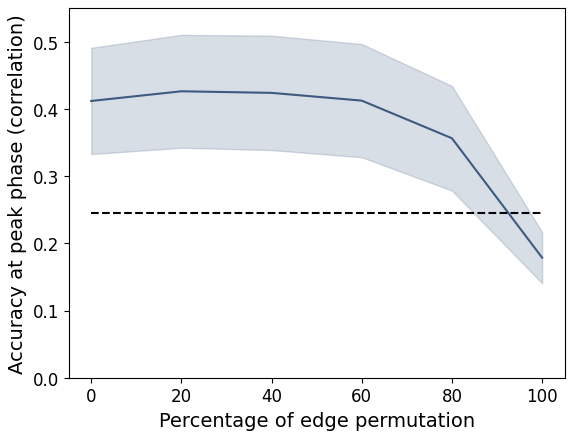</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>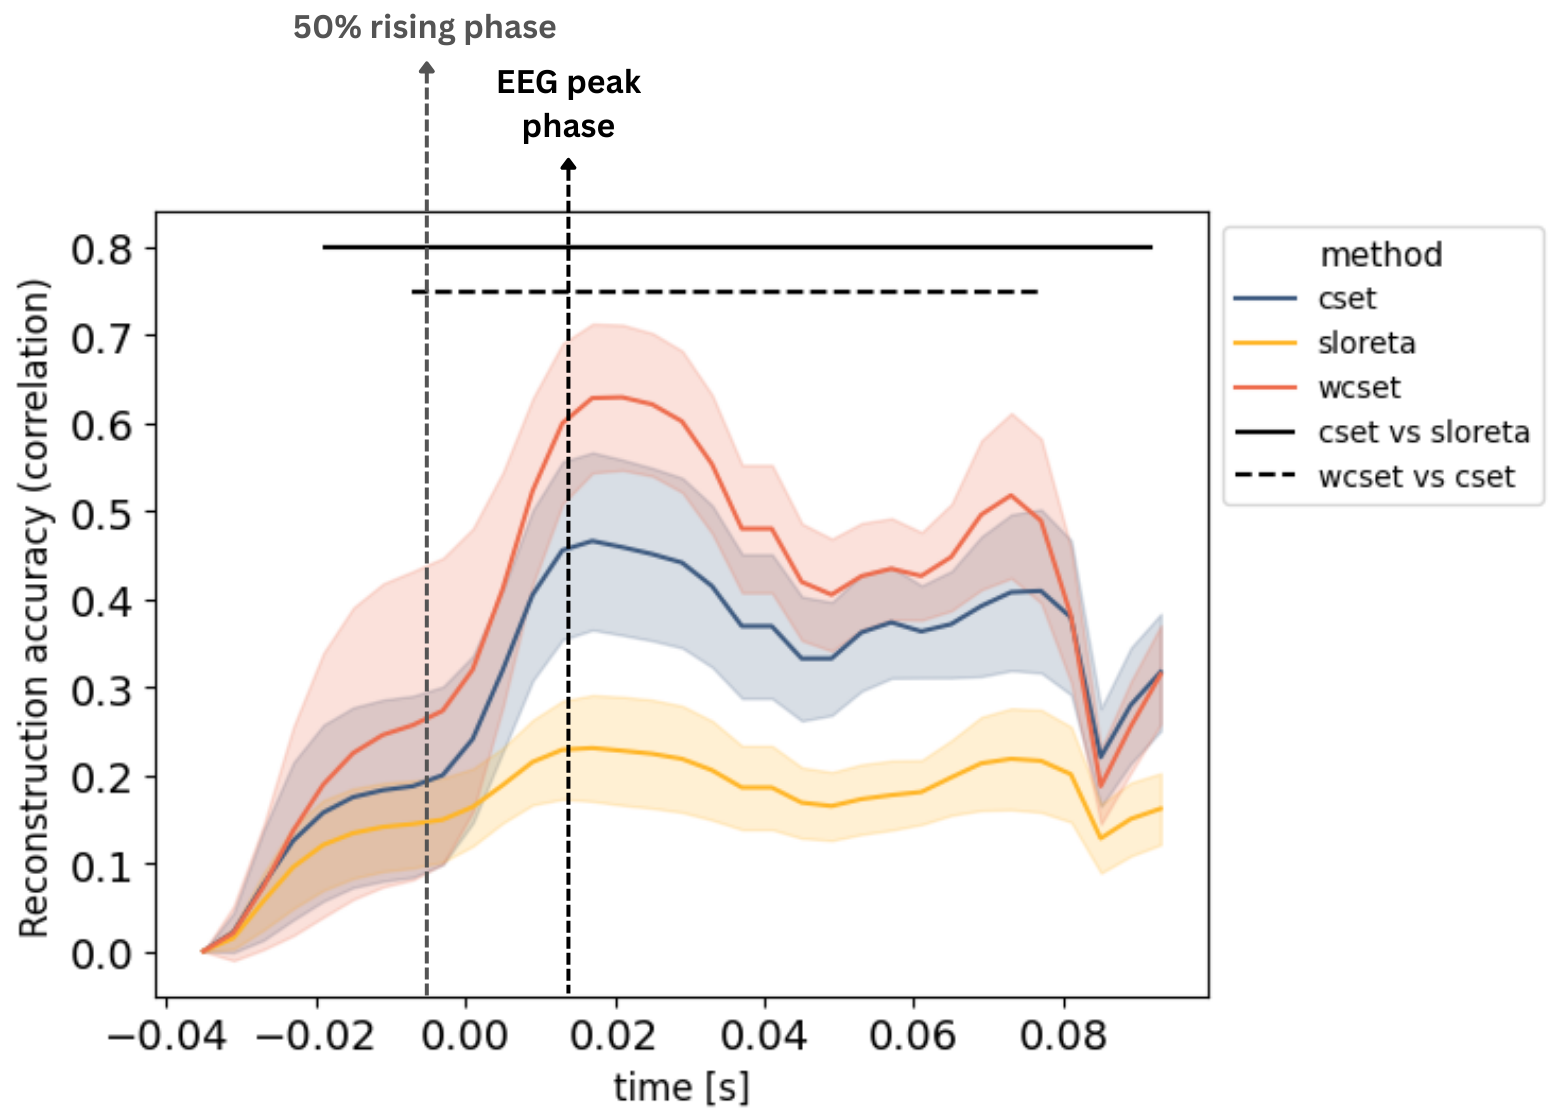</p>
</div></td>
</tr>
</tbody>
</table>

*Reconstruction accuracy*. 2.A) Spatial correlation between CSET reconstructions and the ground truth at the EEG peak phase for different levels of connectome perturbation. 2.B) Spatial correlation with the ground truth over time for CSET, sLORETA, and wCSET. Statistical significance was assessed using a chi-squared goodness-of-fit test with a significance level of 0.05, with a Bonferroni correction applied for multiple comparisons based on the number of time points multiplied by the number of curves. Vertical lines indicate time points at which significant differences were observed (solid lines for the comparison between CSET and sLORETA, and dotted lines for the comparison between wCSET and CSET). Each method was evaluated using 100 different source seeds, with 30 repetitions per seed.

# Conclusion

Figure ([**fig-robust?**](#ref-fig-robust)) shows that the CSET method is highly robust. Even after permuting half of the connections, enough connectivity information remains for the reconstruction accuracy to stay nearly unchanged. By examining the graph Fourier harmonics of the original connectome and the 50%-perturbed connectome, we observed that the low and high harmonics remain similar, whereas the intermediate harmonics change substantially. This phenomenon has been described in previous literature (Sipes, Nagarajan, and Raj ([2024](#ref-sipes_integrative_2024))), where the robust low-frequency harmonics are referred to as integrative, the robust high-frequency harmonics as segregative, and the sensitive intermediate harmonics as degenerative. The same studies relate the robustness of harmonics to the gap spectrum, which quantifies the frequency difference between consecutive harmonics. The literature suggests that integrative harmonics are useful for describing integrative activity (such as spike propagation across the brain), while segregative harmonics are better suited for representing localized activity (such as source onset). Graph Fourier transforms of in-vivo brain activity are also typically shown on a log–log scale because most of the energy in the spectral domain is concentrated in the low-frequency harmonics, further highlighting their importance in representing brain activity.

These observations lead us to believe that the integrative and segregative harmonics contribute most effectively to activity reconstruction. Based on this, we designed a new optimization problem in which the prior remains the Fourier transform but each harmonic is weighted according to the gap spectrum, which closely follows the robustness profile of the harmonics, hence the name weighted-CSET. While CSET seeks to reconstruct a sparse connectome spectrum and thereby introduces compactness, wCSET explicitly builds a compact spectrum by favoring integrative and segregative harmonics and down-weighting degenerative harmonics.

We then evaluated wCSET over the full EEG time window and compared its performance with sLORETA and CSET. In Figure 2B, spatial correlation is low at early time points because the estimates are biased by reduced signal-to-noise ratio (SNR). In future work, we plan to compute precision and recall to mitigate this bias. Nevertheless, for the purposes of this abstract, differences in spatial correlation across methods can still be interpreted as indicators of relative performance. Prior to the 50% rising phase of the spike, correlations are relatively similar across methods. During the EEG peak, however, both CSET and wCSET perform substantially better, as expected: as activity propagates, the underlying sources become more interconnected, and connectivity-informed priors therefore provide a stronger advantage. The weighting strategy employed by wCSET appears to further enhance reconstruction performance.

Overall, this simulation study shows promising potential for extending source imaging from simple source localization toward full reconstruction of source activity patterns by reconstructing the connectome spectrum and hence adding structural connectivity a-priori information. As a next step, we aim to design an *in-vivo* paradigm that allows evaluation of connectivity-driven reconstruction methods. Many paradigms exist for which the relevant connectivity is well documented in the literature; the remaining challenge is to develop effective ways of evaluating reconstruction quality within these paradigms.

## References

Alemán-Gómez, Yasser, Alessandra Griffa, Jean-Christophe Houde, Elena Najdenovska, Stefano Magon, Meritxell Bach Cuadra, Maxime Descoteaux, and Patric Hagmann. 2022. “A Multi-Scale Probabilistic Atlas of the Human Connectome.” *Scientific Data* 9 (1): 516. <https://doi.org/10.1038/s41597-022-01624-8>.

Gonzalez-Moreira, Eduardo, Deirel Paz-Linares, Ariosky Areces-Gonzalez, Rigel Wang, Jorge Bosch-Bayard, Maria Luisa Bringas-Vega, and Pedro A. Valdes-Sosa. 2018. “Caulking the Leakage Effect in MEEG Source Connectivity Analysis.” *arXiv.org*. <https://arxiv.org/abs/1810.00786v2>.

Liu, Ke, Zhu Liang Yu, Wei Wu, Xun Chen, Zhenghui Gu, and Cuntai Guan. 2021. “<span class="nocase">fMRI</span>-SI-STBF: An <span class="nocase">fMRI</span>-Informed Bayesian Electromagnetic Spatio-Temporal Extended Source Imaging.” *Neurocomputing* 462 (October): 14–30. <https://doi.org/10.1016/j.neucom.2021.06.066>.

Pascucci, David, Sebastien Tourbier, Joan Rué-Queralt, Margherita Carboni, Patric Hagmann, and Gijs Plomp. 2022. “Source Imaging of High-Density Visual Evoked Potentials with Multi-Scale Brain Parcellations and Connectomes.” *Scientific Data* 9 (1): 9. <https://doi.org/10.1038/s41597-021-01116-1>.

Rué‐Queralt, Joan, Hugo Fluhr, Sebastien Tourbier, Yasser Aleman‐Gómez, David Pascucci, Jérôme Yerly, Katharina Glomb, Gijs Plomp, and Patric Hagmann. 2024. “Connectome Spectrum Electromagnetic Tomography: A Method to Reconstruct Electrical Brain Source Networks at High‐spatial Resolution.” *Human Brain Mapping* 45 (5): e26638. <https://doi.org/10.1002/hbm.26638>.

Sipes, Benjamin S., Srikantan S. Nagarajan, and Ashish Raj. 2024. “Integrative, Segregative, and Degenerate Harmonics of the Structural Connectome.” *Communications Biology* 7 (1): 986. <https://doi.org/10.1038/s42003-024-06669-6>.
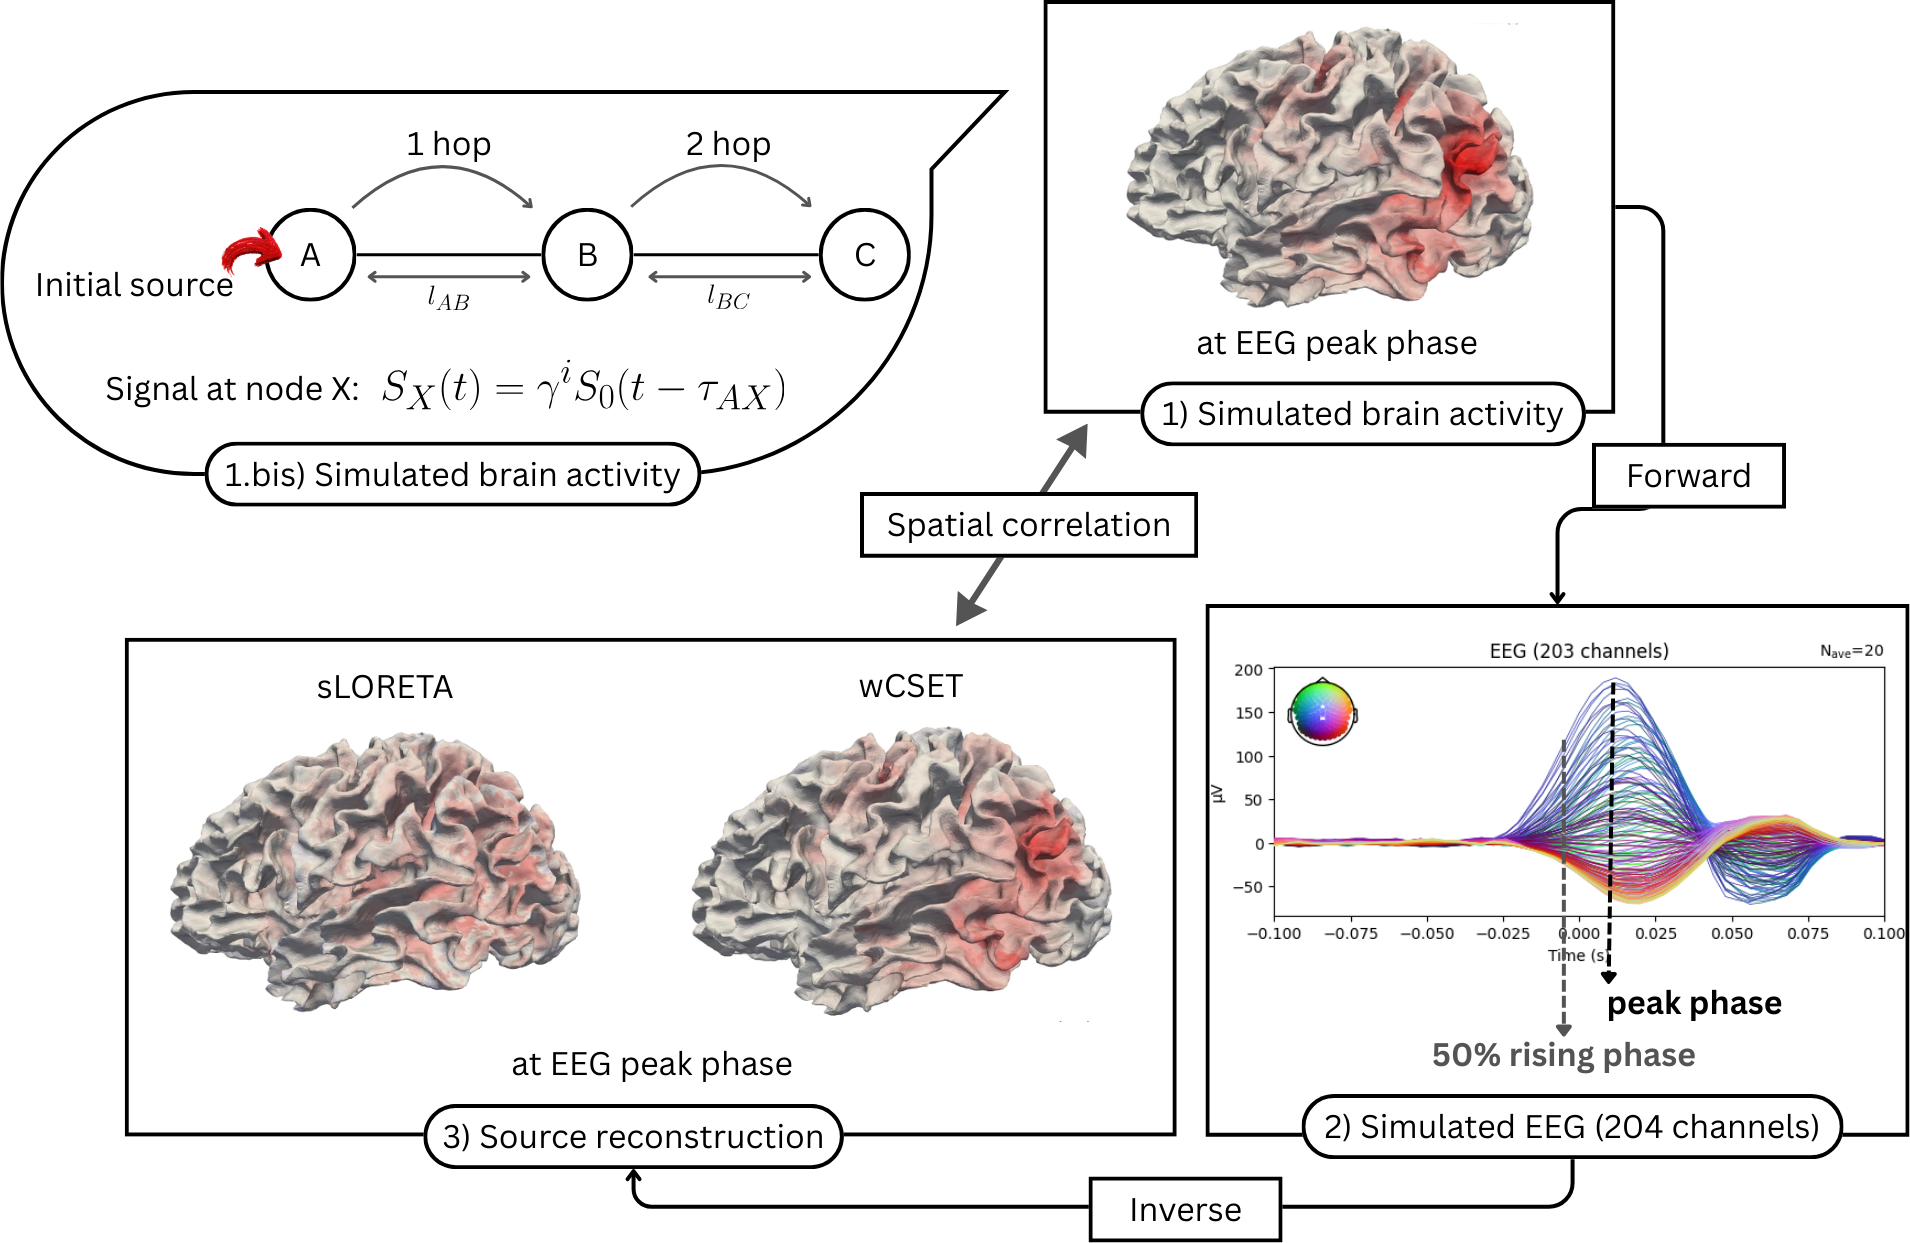